# Dá para prever atraso de entrega na hora da compra? Análise e modelo com a base Olist

Atraso derruba a avaliação do cliente, e esse problema é central para qualquer empresa de delivery. Este notebook faz duas perguntas sobre 96 mil pedidos da Olist:

1. **Onde o atraso se concentra, e quanto ele pesa na nota?**
2. **Dá para prever, na hora da compra, quais pedidos vão atrasar?**

**Resumo.** O atraso atinge 6,8% dos pedidos e vem em picos: três meses têm 22% dos pedidos e 48% dos atrasos. A nota média cai de 4,29 para 2,27 quando a entrega atrasa. O modelo parecia bom na validação (ROC-AUC perto de 0,75), mas caiu para perto de 0,60 no teste, porque o padrão de atraso mudou no meio de 2018. **A principal conclusão: nesta base, o que se sabe na hora da compra não basta para prever atraso em um período novo.**

Cada etapa explica a decisão tomada. As conclusões usam só o que os dados sustentam; o que é hipótese está marcado como hipótese.

**Sobre os números do XGBoost:** eles mudam um pouco entre ambientes. No teste, o ROC-AUC foi de 0,597 na execução publicada no GitHub e de 0,611 na primeira execução no Kaggle, com o mesmo código e os mesmos dados. A análise e a regressão logística não mudaram, e as conclusões são as mesmas nos dois casos.

## 1. Preparação

Todos os arquivos são lidos como texto, com conversão explícita de cada coluna, para nenhuma sujeira passar em silêncio. As validações interrompem a execução quando falham.

In [1]:
# Os resultados do XGBoost mudam um pouco entre ambientes, então as versões usadas ficam registradas aqui.
import importlib.metadata
import platform

print("Python", platform.python_version(), "|", " | ".join(f"{p} {importlib.metadata.version(p)}" for p in ("xgboost", "scikit-learn", "pandas", "numpy")))

Python 3.13.14 | xgboost 3.4.1 | scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4


In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import Markdown, display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

if os.environ.get("OLIST_DIR"):
    DADOS = Path(os.environ["OLIST_DIR"])
else:
    DADOS = next(Path("/kaggle/input").rglob("olist_orders_dataset.csv")).parent

SEED = 42
# Fim do período: na última semana de agosto de 2018, 10,8% dos pedidos ainda não tinham entrega (2% a 3% nas anteriores).
# Manter essa semana esconderia justamente os pedidos que demoram.
INICIO, FIM = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-08-27")
VALIDACAO_INICIO, TESTE_INICIO = pd.Timestamp("2018-04-01"), pd.Timestamp("2018-06-01")
BRASIL = {"lat": (-33.8, 5.3), "lng": (-74.0, -34.7)}
RAIO_TERRA_KM = 6371

AZUL, LARANJA = "#2a78d6", "#eb6834"
SUPERFICIE, TINTA, TINTA_2, GRADE, EIXO = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "font.size": 11, "text.color": TINTA, "axes.labelcolor": TINTA_2, "axes.edgecolor": EIXO, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": TINTA,
})


def pct(x, casas=1):
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def num(x):
    return f"{x:,.0f}".replace(",", ".")


def dec(x, casas=3):
    return f"{x:.{casas}f}".replace(".", ",")


MESES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro", "novembro", "dezembro"]


def nome_periodo(p):
    ano, mes = p.split("-")
    return f"{MESES[int(mes) - 1]} de {ano}"


def ler(nome):
    return pd.read_csv(DADOS / f"olist_{nome}_dataset.csv", dtype=str, keep_default_na=False)


def para_data(s):
    return pd.to_datetime(s.where(s != ""), format="%Y-%m-%d %H:%M:%S")


def para_numero(s):
    return pd.to_numeric(s.where(s != ""))


def distancia_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * RAIO_TERRA_KM * np.arcsin(np.sqrt(a))

### Da tabela de pedidos à base final

**O alvo tem uma armadilha.** A data prometida vem sem hora (00:00). Comparar direto com a data de entrega marca como atrasado quem recebeu **no próprio dia prometido**. Por isso, a comparação é por dia.

**Quem entra:** pedidos entregues e comprados no período. Toda linha que sai aparece na conta abaixo.

In [3]:
pedidos = ler("orders")
for coluna in ("order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"):
    pedidos[coluna] = para_data(pedidos[coluna])
pedidos = pedidos.rename(columns={"order_purchase_timestamp": "compra", "order_delivered_customer_date": "entrega", "order_estimated_delivery_date": "prometida"})

no_periodo = pedidos["compra"].between(INICIO, FIM, inclusive="left")
entregue = (pedidos["order_status"] == "delivered") & pedidos["entrega"].notna()
conta = pd.Series({"Fora do período": (~no_periodo).sum(), "No período, sem entrega registrada": (no_periodo & ~entregue).sum(), "Base final": (no_periodo & entregue).sum()}, name="pedidos")
if conta.sum() != len(pedidos):
    raise ValueError(f"reconciliação falhou: {conta.to_dict()} contra {len(pedidos)}")
base = pedidos[no_periodo & entregue].set_index("order_id")
print(f"Pedidos originais: {num(len(pedidos))}")
display(conta.to_frame())

Pedidos originais: 99.441


,pedidos
Fora do período,479
"No período, sem entrega registrada",2875
Base final,96087


Cada pedido vira uma linha. Pedidos com vários itens somam preço, frete e peso; **categoria e vendedor vêm do item mais caro**. A distância usa o centro de cada prefixo de CEP, sem as coordenadas que caem fora do Brasil.

In [4]:
itens = ler("order_items")
produtos = ler("products")
itens["price"], itens["freight_value"] = itens["price"].astype(float), itens["freight_value"].astype(float)
itens["item"] = itens["order_item_id"].astype(int)
itens["limite_envio"] = para_data(itens["shipping_limit_date"])
produtos["peso_g"] = para_numero(produtos["product_weight_g"]).where(lambda s: s > 0)  # peso zero é falta de dado
produtos["volume_cm3"] = para_numero(produtos["product_length_cm"]) * para_numero(produtos["product_height_cm"]) * para_numero(produtos["product_width_cm"])
itens = itens.merge(produtos[["product_id", "product_category_name", "peso_g", "volume_cm3"]], on="product_id", how="left", validate="m:1")

resumo_itens = itens.groupby("order_id").agg(
    n_itens=("item", "size"), n_vendedores=("seller_id", "nunique"), preco=("price", "sum"), frete=("freight_value", "sum"),
    peso_g=("peso_g", lambda s: s.sum(min_count=1)), volume_cm3=("volume_cm3", lambda s: s.sum(min_count=1)), limite_envio=("limite_envio", "max"))
principal = (itens.sort_values(["order_id", "price", "item"], ascending=[True, False, True]).drop_duplicates("order_id")
             .set_index("order_id")[["seller_id", "product_category_name"]].rename(columns={"product_category_name": "categoria"}))
principal["categoria"] = principal["categoria"].replace("", "sem_categoria")

geo = ler("geolocation")
geo["lat"], geo["lng"] = geo["geolocation_lat"].astype(float), geo["geolocation_lng"].astype(float)
geo = geo[geo["lat"].between(*BRASIL["lat"]) & geo["lng"].between(*BRASIL["lng"])]
centro = geo.groupby("geolocation_zip_code_prefix")[["lat", "lng"]].median()

linhas_antes = len(base)
base = base.join(resumo_itens).join(principal)
base = base.join(ler("customers").set_index("customer_id")[["customer_state", "customer_zip_code_prefix"]], on="customer_id")
base = base.join(ler("sellers").set_index("seller_id")[["seller_state", "seller_zip_code_prefix"]], on="seller_id")
base = base.rename(columns={"customer_state": "uf_cliente", "seller_state": "uf_vendedor"})
cliente, vendedor = centro.reindex(base["customer_zip_code_prefix"]).to_numpy(), centro.reindex(base["seller_zip_code_prefix"]).to_numpy()
base["distancia_km"] = distancia_km(cliente[:, 0], cliente[:, 1], vendedor[:, 0], vendedor[:, 1])

base["dias_atraso"] = (base["entrega"].dt.normalize() - base["prometida"]).dt.days
base["atrasou"] = base["dias_atraso"] > 0
base["prazo_prometido_dias"] = (base["prometida"] - base["compra"]).dt.total_seconds() / 86400
base["dias_ate_limite_envio"] = (base["limite_envio"] - base["compra"]).dt.total_seconds() / 86400
base["mes"], base["dia_semana"] = base["compra"].dt.month, base["compra"].dt.dayofweek
base["mesma_uf"] = base["uf_cliente"] == base["uf_vendedor"]
base["periodo"] = base["compra"].dt.to_period("M").astype(str)

if len(base) != linhas_antes or base.index.duplicated().any():
    raise ValueError("os joins multiplicaram ou perderam pedidos")
if not base["prazo_prometido_dias"].gt(0).all() or not base["distancia_km"].dropna().between(0, 5000).all():
    raise ValueError("prazo ou distância fora do esperado")
if base["uf_cliente"].isna().any() or base["seller_id"].isna().any() or base["categoria"].isna().any():
    raise ValueError("pedido sem cliente, vendedor ou categoria")

TAXA = base["atrasou"].mean()
print(f"Base final: {num(len(base))} pedidos | atraso: {pct(TAXA)}")
print(f"Sem distância (CEP sem coordenada): {num(base['distancia_km'].isna().sum())} | sem peso: {num(base['peso_g'].isna().sum())}. Ficam vazios: não há imputação.")

Base final: 96.087 pedidos | atraso: 6,8%
Sem distância (CEP sem coordenada): 476 | sem peso: 22. Ficam vazios: não há imputação.


C:\Users\User1\AppData\Local\Temp\ipykernel_21220\2441926577.py:34: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  base["mes"], base["dia_semana"] = base["compra"].dt.month, base["compra"].dt.dayofweek


**E se a definição fosse outra?** Rodo a taxa de duas outras formas. A primeira compara com a hora, como faria uma comparação direta. A segunda conta como atrasados os pedidos enviados que nunca tiveram entrega registrada. O nível muda, então vale deixar a definição explícita; a seção 2 confere se a conclusão também muda.

In [5]:
enviados_sem_entrega = int((no_periodo & ~entregue & (pedidos["order_status"] == "shipped")).sum())
display(pd.DataFrame({
    "atraso": [pct(TAXA), pct((base["entrega"] > base["prometida"]).mean()), pct((base["atrasou"].sum() + enviados_sem_entrega) / (len(base) + enviados_sem_entrega))],
}, index=["Por dia (usada aqui)", "Por data e hora", f"Por dia, somando {num(enviados_sem_entrega)} enviados sem entrega"]))

,atraso
Por dia (usada aqui),"6,8%"
Por data e hora,"8,1%"
"Por dia, somando 1.097 enviados sem entrega","7,8%"


## 2. Onde o atraso se concentra

A taxa diz a intensidade; o **excesso** diz o tamanho do problema: quantos atrasos o segmento tem além do que teria na taxa geral. É por ele que os segmentos são ordenados.

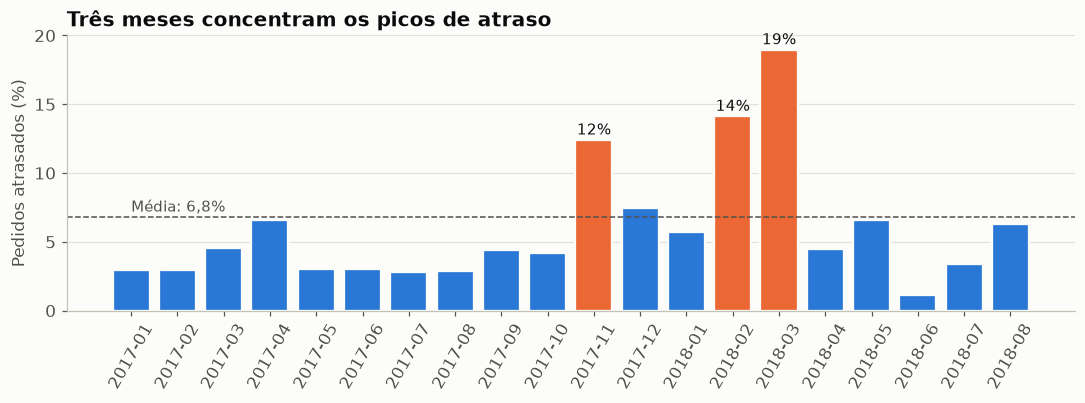

**O atraso vem em picos.** novembro de 2017, fevereiro de 2018 e março de 2018 têm 21,7% dos pedidos e 48,4% dos atrasos. Fora deles, a taxa é de 4,5%. Se os picos tivessem essa taxa, haveria 2.223 atrasos a menos, ou 34,0% do total.

In [6]:
def segmentar(dados, coluna):
    dados = dados[dados[coluna].notna()]
    tabela = dados.groupby(coluna, observed=True)["atrasou"].agg(pedidos="size", atrasos="sum", taxa="mean")
    if tabela["pedidos"].sum() != len(dados):
        raise ValueError(f"{coluna}: a soma dos segmentos não bate com o total")
    tabela["excesso"] = tabela["atrasos"] - tabela["pedidos"] * dados["atrasou"].mean()
    tabela["peso_no_excesso"] = tabela["excesso"].clip(lower=0) / tabela["excesso"].clip(lower=0).sum()
    return tabela


por_mes = segmentar(base, "periodo").sort_index()
PICOS = sorted(por_mes.sort_values("excesso", ascending=False).index[:3])
NOMES_PICOS = ", ".join(nome_periodo(p) for p in PICOS[:-1]) + " e " + nome_periodo(PICOS[-1])
fora_do_pico = base[~base["periodo"].isin(PICOS)]
pico = base[base["periodo"].isin(PICOS)]
TAXA_FORA = fora_do_pico["atrasou"].mean()
excesso_picos = pico["atrasou"].sum() - len(pico) * TAXA_FORA

fig, ax = plt.subplots(figsize=(10, 3.8))
cores = [LARANJA if p in PICOS else AZUL for p in por_mes.index]
ax.bar(por_mes.index, por_mes["taxa"] * 100, color=cores, edgecolor=SUPERFICIE, linewidth=1.5)
ax.axhline(TAXA * 100, color=TINTA_2, linewidth=1, linestyle="--")
ax.text(0, TAXA * 100 + 0.4, f"Média: {pct(TAXA)}", color=TINTA_2, fontsize=10)
for p in PICOS:
    ax.text(p, por_mes.loc[p, "taxa"] * 100 + 0.4, pct(por_mes.loc[p, "taxa"], 0), ha="center", fontsize=10, color=TINTA)
ax.set_title("Três meses concentram os picos de atraso")
ax.set_ylabel("Pedidos atrasados (%)")
ax.set_yticks(range(0, 21, 5))
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

display(Markdown(f"**O atraso vem em picos.** {NOMES_PICOS} têm {pct(len(pico) / len(base))} dos pedidos e {pct(pico['atrasou'].sum() / base['atrasou'].sum())} dos atrasos. "
                 f"Fora deles, a taxa é de {pct(TAXA_FORA)}. Se os picos tivessem essa taxa, haveria {num(excesso_picos)} atrasos a menos, ou {pct(excesso_picos / base['atrasou'].sum())} do total."))

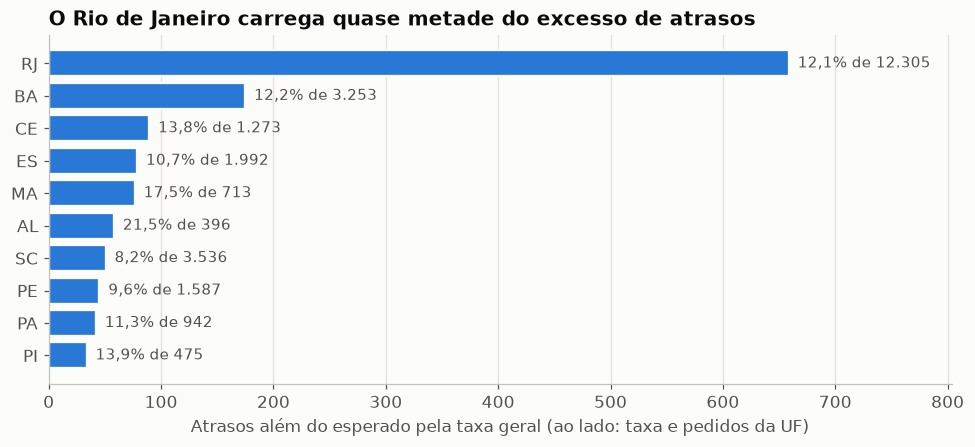

**O maior problema não é a maior taxa.** AL, MA, SE têm as maiores taxas (21,5%, 17,5%, 15,4%), mas pouco volume. O RJ tem taxa de 12,1% e responde por 47,1% do excesso.

In [7]:
por_uf = segmentar(base, "uf_cliente").sort_values("excesso", ascending=False)
principais = por_uf.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(principais.index, principais["excesso"], color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5)
for uf, linha in principais.iterrows():
    ax.text(linha["excesso"] + 8, uf, f"{pct(linha['taxa'])} de {num(linha['pedidos'])}", va="center", fontsize=10, color=TINTA_2)
ax.set_xlim(0, principais["excesso"].max() * 1.22)
ax.set_title("O Rio de Janeiro carrega quase metade do excesso de atrasos")
ax.set_xlabel("Atrasos além do esperado pela taxa geral (ao lado: taxa e pedidos da UF)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

RJ_PESO = por_uf.loc["RJ", "peso_no_excesso"]
por_uf_taxa = por_uf[por_uf["pedidos"] >= 300].sort_values("taxa", ascending=False).head(3)
display(Markdown(f"**O maior problema não é a maior taxa.** {', '.join(por_uf_taxa.index)} têm as maiores taxas ({', '.join(pct(t) for t in por_uf_taxa['taxa'])}), mas pouco volume. "
                 f"O RJ tem taxa de {pct(por_uf.loc['RJ', 'taxa'])} e responde por {pct(RJ_PESO)} do excesso."))

### O Rio é pior mesmo, ou só mais distante?

A UF pode ser só um atalho para a distância. O teste direto é comparar o RJ com o resto **dentro da mesma faixa de distância**, separando picos do resto do período.

In [8]:
FAIXAS = [0, 50, 200, 500, 1000, 2000, 5000]
ROTULOS = ["até 50", "50 a 200", "200 a 500", "500 a 1.000", "1.000 a 2.000", "mais de 2.000"]
base["faixa_km"] = pd.cut(base["distancia_km"], FAIXAS, labels=ROTULOS, include_lowest=True)
base["em_pico"] = base["periodo"].isin(PICOS)
base["grupo_uf"] = np.where(base["uf_cliente"] == "RJ", "RJ", "Resto")

comparacao = (base.pivot_table(index=["em_pico", "faixa_km"], columns="grupo_uf", values="atrasou", aggfunc=["mean", "size"], observed=True))
comparacao.columns = ["taxa_resto" if c == ("mean", "Resto") else "taxa_rj" if c == ("mean", "RJ") else "n_resto" if c == ("size", "Resto") else "n_rj" for c in comparacao.columns]
comparacao = comparacao[["taxa_rj", "n_rj", "taxa_resto", "n_resto"]]
com_volume = comparacao[(comparacao["n_rj"] >= 100) & (comparacao["n_resto"] >= 100)]
rj_pior = int((com_volume["taxa_rj"] > com_volume["taxa_resto"]).sum())
tabela = com_volume.copy()
tabela["taxa_rj"], tabela["taxa_resto"] = tabela["taxa_rj"].map(pct), tabela["taxa_resto"].map(pct)
tabela.index = tabela.index.set_levels(["Fora dos picos", "Nos picos"], level=0)
display(tabela.rename(columns={"taxa_rj": "RJ: taxa", "n_rj": "RJ: pedidos", "taxa_resto": "Resto: taxa", "n_resto": "Resto: pedidos"}))
rj_faixas = base[(base["uf_cliente"] == "RJ") & base["faixa_km"].isin(["200 a 500", "500 a 1.000"])]
PARTE_RJ = len(rj_faixas) / (base["uf_cliente"] == "RJ").sum()
display(Markdown(f"**O efeito sobrevive onde o RJ tem volume.** Com pelo menos 100 pedidos em cada lado, o RJ é pior em {rj_pior} de {len(com_volume)} comparações. Nas faixas de 200 a 1.000 km, que têm {pct(PARTE_RJ, 0)} dos pedidos do RJ, ele é pior nos picos e fora deles; nas outras faixas, o resultado varia. "
                 "A base não tem dado de transportadora, então **a causa segue em aberto**: seria preciso cruzar com as rotas e os operadores do RJ nesses meses."))

RJ: taxa  RJ: pedidos Resto: taxa  Resto: pedidos
em_pico        faixa_km                                                       
Fora dos picos até 50            7,2%          488        4,3%            8840
               50 a 200          1,9%          322        4,0%            9902
               200 a 500         7,0%         5082        2,9%           18451
               500 a 1.000       6,7%         3094        3,4%           16672
               1.000 a 2.000     5,1%          474        6,8%            7129
Nos picos      até 50            1,8%          114        4,8%            2206
               200 a 500        31,7%         1390       11,7%            5208
               500 a 1.000      36,8%         1020       13,9%            4910
               1.000 a 2.000    26,7%          120       19,4%            1982

**O efeito sobrevive onde o RJ tem volume.** Com pelo menos 100 pedidos em cada lado, o RJ é pior em 6 de 9 comparações. Nas faixas de 200 a 1.000 km, que têm 86% dos pedidos do RJ, ele é pior nos picos e fora deles; nas outras faixas, o resultado varia. A base não tem dado de transportadora, então **a causa segue em aberto**: seria preciso cruzar com as rotas e os operadores do RJ nesses meses.

In [9]:
rj_sem_picos = fora_do_pico["uf_cliente"].eq("RJ")
residuo = segmentar(fora_do_pico, "uf_cliente").sort_values("excesso", ascending=False).head(5)
display(Markdown(f"**Tirar os picos não resolve tudo.** Fora deles, ainda há excesso concentrado:"))
tabela = residuo[["pedidos", "taxa", "excesso", "peso_no_excesso"]].copy()
tabela["taxa"], tabela["peso_no_excesso"], tabela["excesso"] = tabela["taxa"].map(pct), tabela["peso_no_excesso"].map(pct), tabela["excesso"].map(num)
display(tabela)

# Mesma conclusão com as outras definições de atraso?
definicoes = {"por dia": base["atrasou"], "por data e hora": base["entrega"] > base["prometida"]}
for nome, alvo in definicoes.items():
    t = segmentar(base.assign(atrasou=alvo), "uf_cliente").sort_values("excesso", ascending=False)
    m = segmentar(base.assign(atrasou=alvo), "periodo").sort_values("excesso", ascending=False)
    print(f"{nome:16} maior excesso por UF: {t.index[0]} ({pct(t['peso_no_excesso'].iloc[0])}) | meses de pico: {sorted(m.index[:3])}")

**Tirar os picos não resolve tudo.** Fora deles, ainda há excesso concentrado:

,pedidos,taxa,excesso,peso_no_excesso
uf_cliente,,,,
RJ,9550,"6,6%",207,"32,6%"
BA,2567,"9,6%",131,"20,6%"
AL,316,"19,3%",47,"7,4%"
PE,1234,"8,3%",47,"7,4%"
ES,1542,"6,9%",38,"6,0%"


por dia          maior excesso por UF: RJ (47,1%) | meses de pico: ['2017-11', '2018-02', '2018-03']
por data e hora  maior excesso por UF: RJ (45,9%) | meses de pico: ['2017-11', '2018-02', '2018-03']


### Distância pesa, mas principalmente nos picos

A intuição diz que entrega longe atrasa mais. Separando os picos, o quadro fica mais preciso.

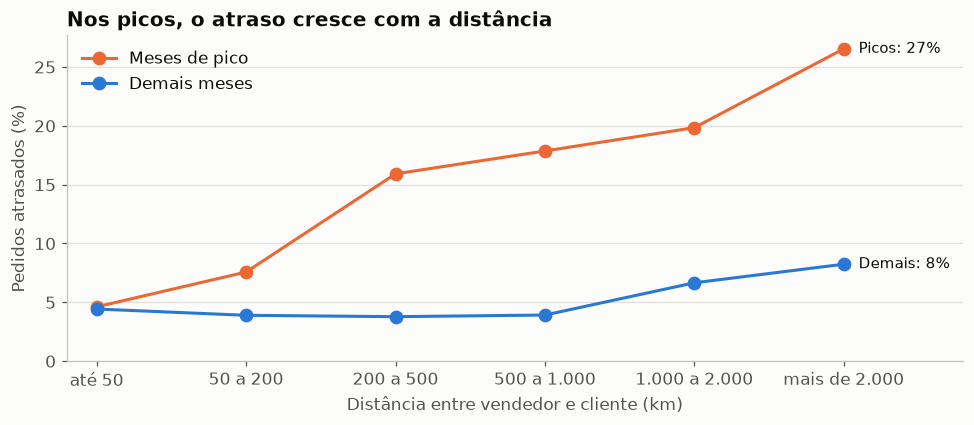

Fora dos picos, a taxa fica estável até 1.000 km (de 4,4% a 3,9%). Nos picos, vai de 4,6% a 26,5%. O prazo prometido já cresce com a distância (mediana de 14 a 33 dias), e isso parece absorver parte do efeito nos meses normais. **Hipótese:** o prazo cobre a distância em condições normais, mas não quando a operação está sob pressão.

In [10]:
por_faixa = base.pivot_table(index="faixa_km", columns="em_pico", values="atrasou", aggfunc="mean", observed=True) * 100
prazo_mediano = base.groupby("faixa_km", observed=True)["prazo_prometido_dias"].median()

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(por_faixa))
ax.plot(x, por_faixa[True], color=LARANJA, linewidth=2, marker="o", markersize=8, label="Meses de pico")
ax.plot(x, por_faixa[False], color=AZUL, linewidth=2, marker="o", markersize=8, label="Demais meses")
ax.text(x[-1] + 0.1, por_faixa[True].iloc[-1], f"Picos: {pct(por_faixa[True].iloc[-1] / 100, 0)}", va="center", color=TINTA, fontsize=10)
ax.text(x[-1] + 0.1, por_faixa[False].iloc[-1], f"Demais: {pct(por_faixa[False].iloc[-1] / 100, 0)}", va="center", color=TINTA, fontsize=10)
ax.set_xticks(x, por_faixa.index)
ax.set_xlim(-0.2, len(x) - 0.2)
ax.set_ylim(0)
ax.set_title("Nos picos, o atraso cresce com a distância")
ax.set_xlabel("Distância entre vendedor e cliente (km)")
ax.set_ylabel("Pedidos atrasados (%)")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

display(Markdown(f"Fora dos picos, a taxa fica estável até 1.000 km (de {pct(por_faixa[False].iloc[0] / 100)} a {pct(por_faixa[False].iloc[3] / 100)}). Nos picos, vai de {pct(por_faixa[True].iloc[0] / 100)} a {pct(por_faixa[True].iloc[-1] / 100)}. "
                 f"O prazo prometido já cresce com a distância (mediana de {dec(prazo_mediano.iloc[0], 0)} a {dec(prazo_mediano.iloc[-1], 0)} dias), e isso parece absorver parte do efeito nos meses normais. "
                 "**Hipótese:** o prazo cobre a distância em condições normais, mas não quando a operação está sob pressão."))

In [11]:
por_categoria = segmentar(base, "categoria").sort_values("excesso", ascending=False)
tabela = por_categoria.head(6)[["pedidos", "taxa", "excesso", "peso_no_excesso"]].copy()
tabela["taxa"], tabela["peso_no_excesso"], tabela["excesso"] = tabela["taxa"].map(pct), tabela["peso_no_excesso"].map(pct), tabela["excesso"].map(num)
display(tabela)
display(Markdown(f"**A categoria pesa pouco.** As maiores têm taxas perto da média geral ({pct(TAXA)}): o excesso delas vem mais do volume do que de uma taxa alta."))

,pedidos,taxa,excesso,peso_no_excesso
categoria,,,,
beleza_saude,8561,"7,6%",65,"17,8%"
cama_mesa_banho,9168,"7,5%",64,"17,4%"
bebes,2749,"8,1%",37,"10,1%"
relogios_presentes,5467,"7,4%",34,"9,4%"
moveis_decoracao,6138,"7,3%",31,"8,4%"
eletronicos,2501,"7,7%",22,"6,0%"


**A categoria pesa pouco.** As maiores têm taxas perto da média geral (6,8%): o excesso delas vem mais do volume do que de uma taxa alta.

## 3. Quanto o atraso pesa na nota

Quando o pedido tem mais de uma avaliação, fica a mais recente.

Pedidos com nota: 95.445 de 96.087


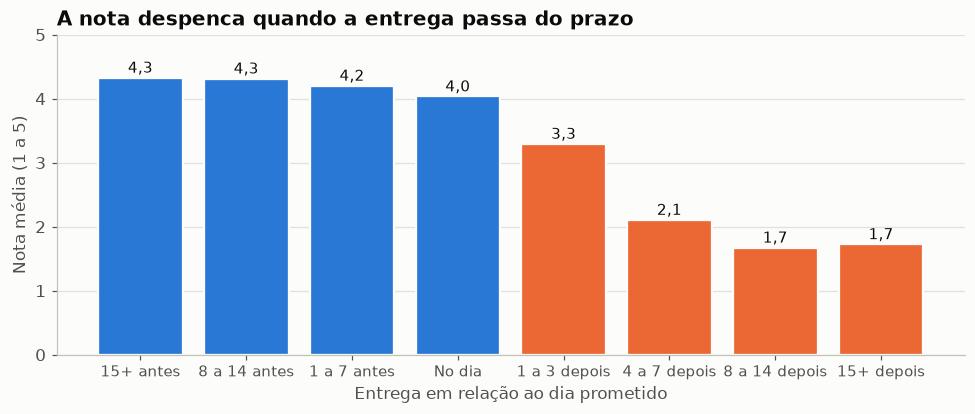

Entrega no prazo: nota **4,29**, com 9,3% de notas 1 ou 2. Com atraso: nota **2,27**, com 62,4%. Se os atrasados tivessem a proporção de notas ruins dos demais, seriam 3.390 notas ruins a menos, ou 27,7% de todas.

In [12]:
avaliacoes = ler("order_reviews")
avaliacoes["nota"], avaliacoes["data_avaliacao"] = avaliacoes["review_score"].astype(int), para_data(avaliacoes["review_creation_date"])
ultima = avaliacoes.sort_values("data_avaliacao").groupby("order_id")[["nota", "data_avaliacao"]].last()
com_nota = base.join(ultima, how="inner")
if com_nota.index.duplicated().any():
    raise ValueError("o join com as avaliações multiplicou pedidos")
if not com_nota["nota"].between(1, 5).all():
    raise ValueError("nota fora de 1 a 5")
print(f"Pedidos com nota: {num(len(com_nota))} de {num(len(base))}")

FAIXAS_ATRASO = [-1000, -15, -8, -1, 0, 3, 7, 14, 1000]
NOMES_ATRASO = ["15+ antes", "8 a 14 antes", "1 a 7 antes", "No dia", "1 a 3 depois", "4 a 7 depois", "8 a 14 depois", "15+ depois"]
com_nota["faixa_atraso"] = pd.cut(com_nota["dias_atraso"], FAIXAS_ATRASO, labels=NOMES_ATRASO)
por_atraso = com_nota.groupby("faixa_atraso", observed=True)["nota"].agg(pedidos="size", media="mean", ruins=lambda s: (s <= 2).mean())

fig, ax = plt.subplots(figsize=(9, 3.9))
cores = [LARANJA if n.endswith("depois") else AZUL for n in por_atraso.index]
ax.bar(por_atraso.index, por_atraso["media"], color=cores, edgecolor=SUPERFICIE, linewidth=1.5)
for nome, linha in por_atraso.iterrows():
    ax.text(nome, linha["media"] + 0.08, dec(linha["media"], 1), ha="center", fontsize=10, color=TINTA)
ax.set_ylim(0, 5)
ax.set_title("A nota despenca quando a entrega passa do prazo")
ax.set_ylabel("Nota média (1 a 5)")
ax.set_xlabel("Entrega em relação ao dia prometido")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", labelsize=9.5)
plt.tight_layout()
plt.show()

atraso = com_nota[com_nota["atrasou"]]
no_prazo = com_nota[~com_nota["atrasou"]]
ruins = com_nota["nota"] <= 2
excesso_ruins = (ruins & com_nota["atrasou"]).sum() - len(atraso) * (no_prazo["nota"] <= 2).mean()
NOTA_NO_PRAZO, NOTA_ATRASO = no_prazo["nota"].mean(), atraso["nota"].mean()
display(Markdown(f"Entrega no prazo: nota **{dec(NOTA_NO_PRAZO, 2)}**, com {pct((no_prazo['nota'] <= 2).mean())} de notas 1 ou 2. Com atraso: nota **{dec(NOTA_ATRASO, 2)}**, com {pct((atraso['nota'] <= 2).mean())}. "
                 f"Se os atrasados tivessem a proporção de notas ruins dos demais, seriam {num(excesso_ruins)} notas ruins a menos, ou {pct(excesso_ruins / ruins.sum())} de todas."))

**Isso é efeito do atraso, ou de outra coisa?** Um vendedor ruim pode atrasar e também vender produto ruim. Por isso, comparo atrasados e no prazo **dentro** da mesma UF, categoria e vendedor, exigindo volume nos dois lados.

In [13]:
linhas = {}
for coluna, nome, minimo in (("uf_cliente", "UF do cliente", 30), ("categoria", "Categoria", 30), ("seller_id", "Vendedor", 20)):
    t = com_nota.pivot_table(index=coluna, columns="atrasou", values="nota", aggfunc=["mean", "size"], observed=True)
    t.columns = ["nota_prazo", "nota_atraso", "n_prazo", "n_atraso"]
    t = t[(t["n_prazo"] >= minimo) & (t["n_atraso"] >= minimo)]
    linhas[nome] = {"grupos com volume": len(t), "nota menor com atraso": int((t["nota_atraso"] < t["nota_prazo"]).sum()), "diferença média": dec((t["nota_atraso"] - t["nota_prazo"]).mean(), 2)}
display(pd.DataFrame(linhas).T)
avaliou_antes = (atraso["data_avaliacao"] < atraso["entrega"].dt.normalize()).mean()
display(Markdown(f"A queda aparece em todos os grupos e se aprofunda até cerca de duas semanas de atraso. É um indício forte, mas **não é prova de causa**, porque não é um experimento. Um detalhe ajuda a entender o tamanho da queda: {pct(avaliou_antes)} dos pedidos atrasados foram avaliados antes da entrega registrada, ou seja, o cliente ainda estava esperando o produto."))

,grupos com volume,nota menor com atraso,diferença média
UF do cliente,21,21,"-2,05"
Categoria,29,29,"-2,02"
Vendedor,53,53,"-2,05"


A queda aparece em todos os grupos e se aprofunda até cerca de duas semanas de atraso. É um indício forte, mas **não é prova de causa**, porque não é um experimento. Um detalhe ajuda a entender o tamanho da queda: 74,4% dos pedidos atrasados foram avaliados antes da entrega registrada, ou seja, o cliente ainda estava esperando o produto.

## 4. O modelo: prever atraso na hora da compra

### Como evitar vazamento

- **Só entra o que se sabe na compra.** Datas de aprovação, envio e entrega ficam de fora, e a avaliação também, porque vem depois.
- **Validação temporal.** Treino no passado, ajustes em abril e maio de 2018 e teste de junho a agosto, usado uma vez só.
- **Só treina com resposta já conhecida.** Um pedido entra no treino se a data prometida venceu antes do corte. O critério usa o prazo, que é conhecido na compra, então não favorece nenhum dos lados: filtrar pela data de entrega tiraria justamente os atrasados.
- **Histórico sem futuro.** As taxas passadas de vendedor e UF só contam entregas concluídas **antes** de cada compra.

In [14]:
def taxa_passada(dados, chave, janela_dias, prefixo):
    """Taxa de atraso entre as entregas concluídas antes de cada compra."""
    partes = []
    for _, g in (dados.groupby(chave, sort=False) if chave else [(None, dados)]):
        ordem = g.sort_values("entrega")
        momentos = ordem["entrega"].to_numpy()
        acumulado = np.r_[0.0, np.cumsum(ordem["atrasou"].to_numpy(dtype=float))]
        fim = np.searchsorted(momentos, g["compra"].to_numpy(), side="left")
        comeco = np.zeros_like(fim) if janela_dias is None else np.searchsorted(momentos, (g["compra"] - pd.Timedelta(days=janela_dias)).to_numpy(), side="left")
        n = fim - comeco
        with np.errstate(invalid="ignore", divide="ignore"):
            taxa = (acumulado[fim] - acumulado[comeco]) / n
        partes.append(pd.DataFrame({f"{prefixo}_n": n, f"{prefixo}_taxa": np.where(n > 0, taxa, np.nan)}, index=g.index))
    return pd.concat(partes).reindex(dados.index)


base = pd.concat([base, taxa_passada(base, "seller_id", None, "vendedor"), taxa_passada(base, "uf_cliente", 30, "uf_recente"), taxa_passada(base, None, 30, "geral_recente")], axis=1)

# Prova de que o histórico não vaza: recalcula na mão, em pedidos sorteados
for _, pedido in base.sample(50, random_state=SEED).iterrows():
    anteriores = base[(base["seller_id"] == pedido["seller_id"]) & (base["entrega"] < pedido["compra"])]
    if len(anteriores) != pedido["vendedor_n"] or (len(anteriores) and abs(anteriores["atrasou"].mean() - pedido["vendedor_taxa"]) > 1e-9):
        raise ValueError("histórico do vendedor não bate com a conta direta")

for coluna in ("uf_cliente", "uf_vendedor", "categoria"):
    base[coluna] = base[coluna].astype("category")

CATEGORICAS = ["uf_cliente", "uf_vendedor", "categoria"]
NUMERICAS = ["distancia_km", "frete", "preco", "peso_g", "volume_cm3", "n_itens", "n_vendedores", "prazo_prometido_dias", "dias_ate_limite_envio", "dia_semana", "mesma_uf"]
HISTORICO = ["vendedor_taxa", "vendedor_n", "uf_recente_taxa", "uf_recente_n", "geral_recente_taxa"]
PROIBIDAS = {"entrega", "dias_atraso", "atrasou", "nota", "faixa_km", "em_pico", "periodo", "prometida"}
if PROIBIDAS & set(CATEGORICAS + NUMERICAS + HISTORICO + ["mes"]):
    raise ValueError("feature com informação do futuro")

treino = base[base["prometida"] < VALIDACAO_INICIO]
validacao = base[(base["compra"] >= VALIDACAO_INICIO) & (base["compra"] < TESTE_INICIO)]
treino_final = base[base["prometida"] < TESTE_INICIO]
teste = base[base["compra"] >= TESTE_INICIO]
if treino["entrega"].dt.normalize().where(treino["atrasou"]).dropna().lt(treino["prometida"][treino["atrasou"]]).any():
    raise ValueError("atraso antes da data prometida")
if teste["compra"].min() < treino_final["compra"].max():
    raise ValueError("o treino final avança sobre o teste")
display(pd.DataFrame({"pedidos": [len(treino), len(validacao), len(treino_final), len(teste)], "atraso": [pct(p["atrasou"].mean()) for p in (treino, validacao, treino_final, teste)],
                      "compras de": [p["compra"].min().date() for p in (treino, validacao, treino_final, teste)], "até": [p["compra"].max().date() for p in (treino, validacao, treino_final, teste)]},
                     index=["Treino", "Validação", "Treino final (treino + validação)", "Teste"]))

,pedidos,atraso,compras de,até
Treino,58912,"7,2%",2017-01-05,2018-03-19
Validação,13547,"5,5%",2018-04-01,2018-05-31
Treino final (treino + validação),73330,"7,6%",2017-01-05,2018-05-22
Teste,18487,"3,6%",2018-06-01,2018-08-26


### Escolha do modelo na validação

A classe de atraso é minoritária, então a métrica principal é o **PR-AUC**. Um classificador sem nenhuma informação fica na taxa de atraso do período. Comparo as combinações de features, incluindo o `mês` que o plano original previa.

In [15]:
PARAMETROS = dict(learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=2,
                  tree_method="hist", enable_categorical=True, max_cat_to_onehot=4, random_state=SEED, n_jobs=4)
VARIANTES = {
    "Com mês": NUMERICAS + ["mes"] + CATEGORICAS,
    "Sem mês": NUMERICAS + CATEGORICAS,
    "Sem mês, com histórico": NUMERICAS + HISTORICO + CATEGORICAS,
    "Com mês e histórico": NUMERICAS + ["mes"] + HISTORICO + CATEGORICAS,
}


def medir(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}


linhas, arvores = {}, {}
for nome, features in VARIANTES.items():
    modelo = xgb.XGBClassifier(n_estimators=1500, eval_metric="aucpr", early_stopping_rounds=60, **PARAMETROS)
    modelo.fit(treino[features], treino["atrasou"], eval_set=[(validacao[features], validacao["atrasou"])], verbose=False)
    arvores[nome] = modelo.best_iteration + 1
    linhas[nome] = {**medir(validacao["atrasou"], modelo.predict_proba(validacao[features])[:, 1]), "árvores": str(arvores[nome])}

ESCOLHIDA = max(linhas, key=lambda n: linhas[n]["PR-AUC"])
FEATURES = VARIANTES[ESCOLHIDA]
COLUNAS_LOGISTICA = NUMERICAS
logistica = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
logistica.fit(treino[COLUNAS_LOGISTICA].astype(float), treino["atrasou"])
linhas["Regressão logística (só numéricas)"] = {**medir(validacao["atrasou"], logistica.predict_proba(validacao[COLUNAS_LOGISTICA].astype(float))[:, 1]), "árvores": "-"}
linhas["Sem informação (taxa do período)"] = {"ROC-AUC": 0.5, "PR-AUC": validacao["atrasou"].mean(), "árvores": "-"}
tabela_validacao = pd.DataFrame(linhas).T
display(tabela_validacao.assign(**{c: tabela_validacao[c].astype(float).map(dec) for c in ("ROC-AUC", "PR-AUC")}))
display(Markdown(f"**Escolhida: {ESCOLHIDA}.** O `mês` piorou o resultado. **Hipótese:** o treino só cobre um ano e meio, então o modelo memoriza os picos de cada mês, e esses picos não se repetem. As taxas históricas também não ajudaram. A regressão logística ficou muito perto, mas a regra era escolher pelo PR-AUC."))

,ROC-AUC,PR-AUC,árvores
Com mês,"0,665","0,131",153
Sem mês,"0,743","0,156",199
"Sem mês, com histórico","0,732","0,147",243
Com mês e histórico,"0,712","0,140",257
Regressão logística (só numéricas),"0,751","0,153",-
Sem informação (taxa do período),"0,500","0,055",-


**Escolhida: Sem mês.** O `mês` piorou o resultado. **Hipótese:** o treino só cobre um ano e meio, então o modelo memoriza os picos de cada mês, e esses picos não se repetem. As taxas históricas também não ajudaram. A regressão logística ficou muito perto, mas a regra era escolher pelo PR-AUC.

### Resultado final no teste

O modelo é retreinado com treino e validação, com o número de árvores definido antes, e roda uma vez só no teste. O intervalo vem de bootstrap, sorteando pedidos do teste.

In [16]:
final = xgb.XGBClassifier(n_estimators=arvores[ESCOLHIDA], **PARAMETROS).fit(treino_final[FEATURES], treino_final["atrasou"])
logistica_final = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
logistica_final.fit(treino_final[COLUNAS_LOGISTICA].astype(float), treino_final["atrasou"])

y_teste = teste["atrasou"].to_numpy()
p_xgb = final.predict_proba(teste[FEATURES])[:, 1]
p_log = logistica_final.predict_proba(teste[COLUNAS_LOGISTICA].astype(float))[:, 1]

rng = np.random.default_rng(SEED)
amostras = []
for _ in range(1000):
    i = rng.integers(len(y_teste), size=len(y_teste))
    amostras.append((*medir(y_teste[i], p_xgb[i]).values(), *medir(y_teste[i], p_log[i]).values()))
amostras = np.array(amostras)
ic = lambda col: np.percentile(amostras[:, col], [2.5, 97.5])
M_XGB, M_LOG = medir(y_teste, p_xgb), medir(y_teste, p_log)
PREVALENCIA = y_teste.mean()
faixa = lambda x: f"{dec(x[0])} a {dec(x[1])}"
display(pd.DataFrame({
    "ROC-AUC": [dec(M_XGB["ROC-AUC"]), dec(M_LOG["ROC-AUC"]), dec(0.5, 3)],
    "ROC-AUC (95%)": [faixa(ic(0)), faixa(ic(2)), "-"],
    "PR-AUC": [dec(M_XGB["PR-AUC"]), dec(M_LOG["PR-AUC"]), dec(PREVALENCIA)],
    "PR-AUC (95%)": [faixa(ic(1)), faixa(ic(3)), "-"],
}, index=["XGBoost", "Regressão logística", "Sem informação"]))
dif_pr = np.percentile(amostras[:, 1] - amostras[:, 3], [2.5, 97.5])
print(f"XGBoost menos logística em PR-AUC: {dec(M_XGB['PR-AUC'] - M_LOG['PR-AUC'])} (95%: {faixa(dif_pr)})")
print(f"Validação: PR-AUC {dec(linhas[ESCOLHIDA]['PR-AUC'])}, com {pct(validacao['atrasou'].mean())} de atraso | Teste: PR-AUC {dec(M_XGB['PR-AUC'])}, com {pct(PREVALENCIA)} de atraso")

,ROC-AUC,ROC-AUC (95%),PR-AUC,PR-AUC (95%)
XGBoost,"0,597","0,575 a 0,617","0,058","0,051 a 0,069"
Regressão logística,"0,669","0,652 a 0,686","0,067","0,059 a 0,080"
Sem informação,"0,500",-,"0,036",-


XGBoost menos logística em PR-AUC: -0,009 (95%: -0,019 a -0,001)
Validação: PR-AUC 0,156, com 5,5% de atraso | Teste: PR-AUC 0,058, com 3,6% de atraso


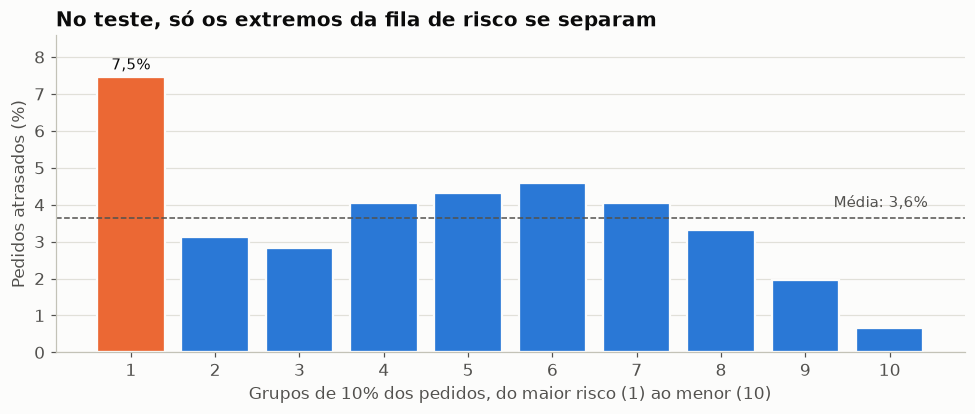

Os 10% de maior risco atrasam 7,5%, contra 3,6% da média, e pegam 20,5% dos atrasos. Com 30% dos pedidos, a fila pega 36,9%, pouco mais do que os 30% de um sorteio. **Do grupo 2 ao 8, a ordem praticamente não diz nada.**

In [17]:
decis = pd.DataFrame({"atrasou": y_teste, "risco": p_xgb})
decis["decil"] = 10 - pd.qcut(decis["risco"].rank(method="first"), 10, labels=False)
por_decil = decis.groupby("decil")["atrasou"].agg(pedidos="size", atrasos="sum", taxa="mean")
por_decil["acumulado"] = por_decil["atrasos"].cumsum() / por_decil["atrasos"].sum()
if por_decil["atrasos"].sum() != y_teste.sum():
    raise ValueError("os decis não somam todos os atrasos")

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.bar(por_decil.index, por_decil["taxa"] * 100, color=[LARANJA] + [AZUL] * 9, edgecolor=SUPERFICIE, linewidth=1.5)
ax.axhline(PREVALENCIA * 100, color=TINTA_2, linestyle="--", linewidth=1)
ax.text(10.45, PREVALENCIA * 100 + 0.3, f"Média: {pct(PREVALENCIA)}", ha="right", color=TINTA_2, fontsize=10)
ax.text(1, por_decil["taxa"].iloc[0] * 100 + 0.2, pct(por_decil["taxa"].iloc[0]), ha="center", fontsize=10)
ax.set_ylim(0, por_decil["taxa"].max() * 100 * 1.15)
ax.set_xticks(por_decil.index)
ax.set_title("No teste, só os extremos da fila de risco se separam")
ax.set_xlabel("Grupos de 10% dos pedidos, do maior risco (1) ao menor (10)")
ax.set_ylabel("Pedidos atrasados (%)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

P10, R10, R30 = por_decil["taxa"].iloc[0], por_decil["acumulado"].iloc[0], por_decil["acumulado"].iloc[2]
display(Markdown(f"Os 10% de maior risco atrasam {pct(P10)}, contra {pct(PREVALENCIA)} da média, e pegam {pct(R10)} dos atrasos. Com 30% dos pedidos, a fila pega {pct(R30)}, pouco mais do que os 30% de um sorteio. **Do grupo 2 ao 8, a ordem praticamente não diz nada.**"))

### Por que o teste foi tão pior que a validação?

Este diagnóstico foi feito **depois** de ver o resultado do teste. Ele serve para entender a queda e não muda o modelo: trocar agora invalidaria o teste como medida.

In [18]:
teste_diag = teste.assign(p_xgb=p_xgb, p_log=p_log, mes_nome=teste["compra"].dt.to_period("M").astype(str))
linhas_mes, DIAG = {}, {}
for mes, g in teste_diag.groupby("mes_nome"):
    DIAG[mes] = {"prazo": g["prazo_prometido_dias"].median(), "roc_xgb": roc_auc_score(g["atrasou"], g["p_xgb"]), "roc_log": roc_auc_score(g["atrasou"], g["p_log"]), "atraso": g["atrasou"].mean()}
    linhas_mes[mes] = {"pedidos": num(len(g)), "atraso": pct(g["atrasou"].mean()), "prazo mediano (dias)": dec(g["prazo_prometido_dias"].median(), 1),
                       "ROC XGBoost": dec(roc_auc_score(g["atrasou"], g["p_xgb"])), "ROC logística": dec(roc_auc_score(g["atrasou"], g["p_log"]))}
display(pd.DataFrame(linhas_mes).T)

# O que mudou entre o treino e o teste
comparar = pd.DataFrame({"Treino final": treino_final.groupby("uf_cliente", observed=True)["atrasou"].mean(), "Teste": teste.groupby("uf_cliente", observed=True)["atrasou"].mean(), "pedidos no teste": teste.groupby("uf_cliente", observed=True).size()})
comparar = comparar.loc[["SP", "RJ", "MG", "RS", "PR", "BA"]]
display(comparar.assign(**{"Treino final": comparar["Treino final"].map(pct), "Teste": comparar["Teste"].map(pct)}))
faixas_prazo = [0, 10, 15, 20, 25, 30, 200]
nomes_prazo = ["até 10", "10 a 15", "15 a 20", "20 a 25", "25 a 30", "mais de 30"]
por_prazo = pd.DataFrame({nome: d.groupby(pd.cut(d["prazo_prometido_dias"], faixas_prazo, labels=nomes_prazo), observed=True)["atrasou"].agg(["mean", "size"]).pipe(lambda t: t["mean"].map(pct) + " de " + t["size"].map(num)) for nome, d in (("Treino final", treino_final), ("Teste", teste))})
por_prazo.index.name = "prazo prometido (dias)"
display(por_prazo)

taxa_uf = lambda d, uf: d.loc[d["uf_cliente"] == uf, "atrasou"].mean()
curtos = lambda d: (d["prazo_prometido_dias"] <= 10).sum()
RJ_TREINO, RJ_TESTE = taxa_uf(treino_final, "RJ"), taxa_uf(teste, "RJ")
display(Markdown(f"""**O padrão mudou no período de teste, de três formas:**

- **O prazo prometido encolheu.** A mediana foi de {dec(DIAG['2018-06']['prazo'], 1)} dias em junho para {dec(DIAG['2018-08']['prazo'], 1)} em agosto. Pedidos com até 10 dias de prazo eram {num(curtos(treino_final))} em todo o treino e {num(curtos(teste))} só no teste.
- **O risco mudou de lugar.** No teste, os pedidos com até 10 dias de prazo atrasam {pct(teste.loc[teste['prazo_prometido_dias'] <= 10, 'atrasou'].mean())}, contra {pct(teste.loc[teste['prazo_prometido_dias'] > 30, 'atrasou'].mean())} acima de 30 dias, e concentram {pct(teste.loc[teste['prazo_prometido_dias'] <= 10, 'atrasou'].sum() / teste['atrasou'].sum())} dos atrasos.
- **O Rio deixou de se destacar.** O RJ foi de {pct(RJ_TREINO)} de atraso no treino para {pct(RJ_TESTE)} no teste, enquanto SP ficou em {pct(taxa_uf(teste, 'SP'))}.

Junto com isso, a qualidade do modelo cai mês a mês: ROC-AUC de {dec(DIAG['2018-06']['roc_xgb'])} em junho e {dec(DIAG['2018-08']['roc_xgb'])} em agosto, pior que um sorteio. O modelo aprendeu um padrão que deixou de valer. A base não diz por que os prazos encolheram: isso seria uma pergunta para quem opera a promessa de entrega.
"""))

,pedidos,atraso,prazo mediano (dias),ROC XGBoost,ROC logística
2018-06,6.096,"1,2%","27,3","0,755","0,751"
2018-07,6.156,"3,4%","19,3","0,627","0,615"
2018-08,6.235,"6,3%","13,5","0,447","0,540"


,Treino final,Teste,pedidos no teste
uf_cliente,,,
SP,"4,4%","4,8%",8510
RJ,"14,7%","3,2%",2121
MG,"5,1%","1,0%",2055
RS,"7,2%","2,0%",903
PR,"4,3%","1,7%",943
BA,"13,6%","4,5%",602


,Treino final,Teste
prazo prometido (dias),,
até 10,"7,4% de 1.035","12,0% de 2.803"
10 a 15,"4,3% de 6.758","3,3% de 3.198"
15 a 20,"7,7% de 12.709","2,6% de 3.173"
20 a 25,"8,9% de 22.119","2,5% de 3.279"
25 a 30,"8,0% de 16.237","1,7% de 2.507"
mais de 30,"6,3% de 14.472","0,7% de 3.527"


**O padrão mudou no período de teste, de três formas:**

- **O prazo prometido encolheu.** A mediana foi de 27,3 dias em junho para 13,5 em agosto. Pedidos com até 10 dias de prazo eram 1.035 em todo o treino e 2.803 só no teste.
- **O risco mudou de lugar.** No teste, os pedidos com até 10 dias de prazo atrasam 12,0%, contra 0,7% acima de 30 dias, e concentram 50,0% dos atrasos.
- **O Rio deixou de se destacar.** O RJ foi de 14,7% de atraso no treino para 3,2% no teste, enquanto SP ficou em 4,8%.

Junto com isso, a qualidade do modelo cai mês a mês: ROC-AUC de 0,755 em junho e 0,447 em agosto, pior que um sorteio. O modelo aprendeu um padrão que deixou de valer. A base não diz por que os prazos encolheram: isso seria uma pergunta para quem opera a promessa de entrega.


**E se a divisão fosse aleatória?** Treino o mesmo modelo sorteando 20% dos pedidos para teste, sem respeitar o tempo. Esse número não serve como resultado: ele só mostra o que uma validação comum teria prometido.

In [19]:
sorteio = np.random.default_rng(SEED).random(len(base)) < 0.2
aleatorio = xgb.XGBClassifier(n_estimators=arvores[ESCOLHIDA], **PARAMETROS).fit(base.loc[~sorteio, FEATURES], base.loc[~sorteio, "atrasou"])
M_ALEATORIO = medir(base.loc[sorteio, "atrasou"], aleatorio.predict_proba(base.loc[sorteio, FEATURES])[:, 1])
TAXA_SORTEIO = base.loc[sorteio, "atrasou"].mean()
display(pd.DataFrame({"ROC-AUC": [dec(M_ALEATORIO["ROC-AUC"]), dec(linhas[ESCOLHIDA]["ROC-AUC"]), dec(M_XGB["ROC-AUC"])], "PR-AUC": [dec(M_ALEATORIO["PR-AUC"]), dec(linhas[ESCOLHIDA]["PR-AUC"]), dec(M_XGB["PR-AUC"])],
                      "atraso no período": [pct(TAXA_SORTEIO), pct(validacao["atrasou"].mean()), pct(PREVALENCIA)]}, index=["Divisão aleatória", "Validação temporal", "Teste temporal"]))

,ROC-AUC,PR-AUC,atraso no período
Divisão aleatória,"0,740","0,190","6,7%"
Validação temporal,"0,743","0,156","5,5%"
Teste temporal,"0,597","0,058","3,6%"


**A validação teria como avisar?** Refaço o treino mês a mês, sempre com dados anteriores ao mês avaliado, em meses **antes** do teste. É o que deveria ter sido feito antes de confiar em uma validação só.

In [20]:
linhas_rolagem = {}
for inicio_mes in pd.date_range("2017-11-01", "2018-05-01", freq="MS"):
    fim_mes = inicio_mes + pd.offsets.MonthBegin(1)
    passado = base[base["prometida"] < inicio_mes]
    avaliado = base[(base["compra"] >= inicio_mes) & (base["compra"] < fim_mes)]
    risco = xgb.XGBClassifier(n_estimators=arvores[ESCOLHIDA], **PARAMETROS).fit(passado[FEATURES], passado["atrasou"]).predict_proba(avaliado[FEATURES])[:, 1]
    linhas_rolagem[str(inicio_mes)[:7]] = {"atraso": avaliado["atrasou"].mean(), "ROC-AUC": roc_auc_score(avaliado["atrasou"], risco)}
rolagem = pd.DataFrame(linhas_rolagem).T
display(rolagem.assign(atraso=rolagem["atraso"].map(pct), **{"ROC-AUC": rolagem["ROC-AUC"].map(dec)}))
ROC_MES_MIN, ROC_MES_MAX = rolagem["ROC-AUC"].min(), rolagem["ROC-AUC"].max()
display(Markdown(f"**Avisaria.** Mês a mês, o ROC-AUC vai de {dec(ROC_MES_MIN)} a {dec(ROC_MES_MAX)}, e os dois meses da validação (abril e maio de 2018) ficam entre os melhores. A divisão aleatória ({dec(M_ALEATORIO['ROC-AUC'])}) e a validação temporal ({dec(linhas[ESCOLHIDA]['ROC-AUC'])}) prometiam quase o mesmo número, e nenhuma das duas antecipou os {dec(M_XGB['ROC-AUC'])} do teste. **A lição do projeto é esta: uma validação temporal única também pode enganar, e olhar a variação entre vários períodos mostra melhor o risco.**"))

,atraso,ROC-AUC
2017-11,"12,4%","0,613"
2017-12,"7,5%","0,631"
2018-01,"5,7%","0,657"
2018-02,"14,1%","0,700"
2018-03,"19,0%","0,685"
2018-04,"4,5%","0,761"
2018-05,"6,6%","0,721"


**Avisaria.** Mês a mês, o ROC-AUC vai de 0,613 a 0,761, e os dois meses da validação (abril e maio de 2018) ficam entre os melhores. A divisão aleatória (0,740) e a validação temporal (0,743) prometiam quase o mesmo número, e nenhuma das duas antecipou os 0,597 do teste. **A lição do projeto é esta: uma validação temporal única também pode enganar, e olhar a variação entre vários períodos mostra melhor o risco.**

## 5. O que o modelo usa: SHAP

Os valores SHAP vêm do próprio XGBoost (`pred_contribs`, que implementa o TreeSHAP). Eles mostram quanto cada feature empurrou o risco de cada pedido, e não dizem o que causa o atraso.

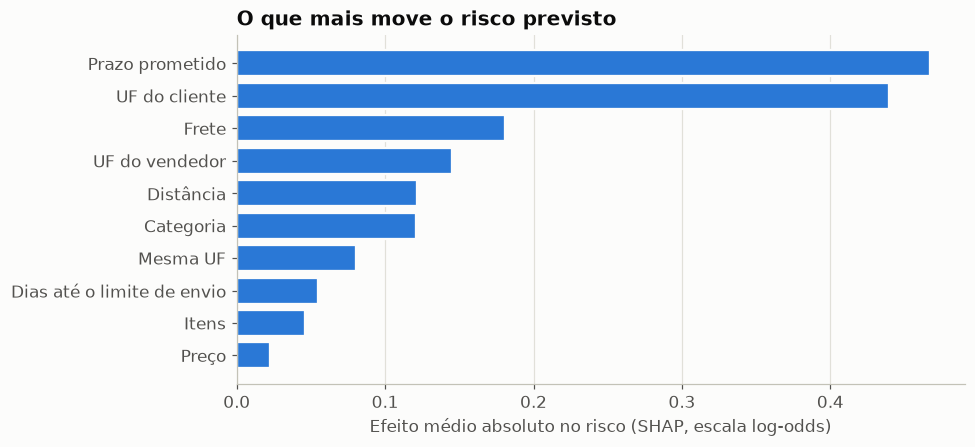

As duas features que mais pesam são **Prazo prometido** e **UF do cliente**, justamente as que mudaram de comportamento no teste. Isso ajuda a entender por que o modelo envelheceu tão rápido.

In [21]:
contribuicoes = final.get_booster().predict(xgb.DMatrix(teste[FEATURES], enable_categorical=True), pred_contribs=True)[:, :-1]
importancia = pd.Series(np.abs(contribuicoes).mean(axis=0), index=FEATURES).sort_values(ascending=False)
NOMES = {"prazo_prometido_dias": "Prazo prometido", "distancia_km": "Distância", "uf_cliente": "UF do cliente", "uf_vendedor": "UF do vendedor", "categoria": "Categoria", "frete": "Frete", "preco": "Preço",
         "peso_g": "Peso", "volume_cm3": "Volume", "dias_ate_limite_envio": "Dias até o limite de envio", "dia_semana": "Dia da semana", "n_itens": "Itens", "n_vendedores": "Vendedores", "mesma_uf": "Mesma UF",
         "mes": "Mês", "vendedor_taxa": "Atraso passado do vendedor", "vendedor_n": "Pedidos passados do vendedor", "uf_recente_taxa": "Atraso recente da UF", "uf_recente_n": "Pedidos recentes da UF", "geral_recente_taxa": "Atraso recente geral"}

fig, ax = plt.subplots(figsize=(9, 4.2))
mostrar = importancia.head(10).iloc[::-1]
ax.barh([NOMES[f] for f in mostrar.index], mostrar, color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5)
ax.set_title("O que mais move o risco previsto")
ax.set_xlabel("Efeito médio absoluto no risco (SHAP, escala log-odds)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
display(Markdown(f"As duas features que mais pesam são **{NOMES[importancia.index[0]]}** e **{NOMES[importancia.index[1]]}**, justamente as que mudaram de comportamento no teste. Isso ajuda a entender por que o modelo envelheceu tão rápido."))

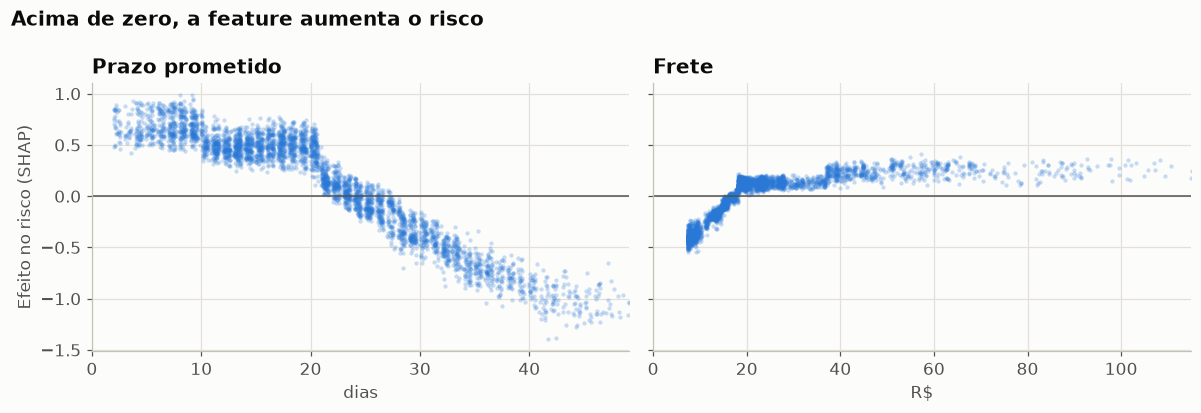

Entre as UFs de cliente com pelo menos 100 pedidos no teste, as que mais aumentam o risco são **PA, MA, CE**; as que mais reduzem, **SP, MG, PR**.

In [22]:
numericas_top = [f for f in importancia.index if f in NUMERICAS and f not in ("dia_semana", "mesma_uf")][:2]
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
amostra = rng.choice(len(teste), size=min(4000, len(teste)), replace=False)
for ax, f in zip(eixos, numericas_top):
    x = teste[f].to_numpy(dtype=float)[amostra]
    ax.scatter(x, contribuicoes[amostra, FEATURES.index(f)], s=8, color=AZUL, alpha=0.25, linewidths=0)
    ax.axhline(0, color=TINTA_2, linewidth=1)
    ax.set_xlim(0, np.nanpercentile(x, 99))
    ax.set_title(NOMES[f])
    ax.set_xlabel({"prazo_prometido_dias": "dias", "distancia_km": "km", "frete": "R$", "dias_ate_limite_envio": "dias", "preco": "R$", "peso_g": "g", "volume_cm3": "cm³"}.get(f, ""))
eixos[0].set_ylabel("Efeito no risco (SHAP)")
fig.suptitle("Acima de zero, a feature aumenta o risco", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

por_uf_shap = pd.Series(contribuicoes[:, FEATURES.index("uf_cliente")], index=teste["uf_cliente"].astype(str)).groupby(level=0).agg(["mean", "size"])
por_uf_shap = por_uf_shap[por_uf_shap["size"] >= 100].sort_values("mean", ascending=False)
display(Markdown(f"Entre as UFs de cliente com pelo menos 100 pedidos no teste, as que mais aumentam o risco são **{', '.join(por_uf_shap.index[:3])}**; as que mais reduzem, **{', '.join(por_uf_shap.index[-3:])}**."))

## 6. Conclusões

In [23]:
display(Markdown(f"""
### O que os dados mostram

- **O atraso vem em picos.** {NOMES_PICOS} têm {pct(len(pico) / len(base))} dos pedidos e {pct(pico['atrasou'].sum() / base['atrasou'].sum())} dos atrasos. A base não explica por quê.
- **O peso do Rio de Janeiro foi grande, mas não durou.** O RJ responde por {pct(RJ_PESO)} do excesso de atrasos da base toda, mas caiu de {pct(RJ_TREINO)} para {pct(RJ_TESTE)} de atraso no período de teste.
- **Atraso e nota ruim andam juntos.** A nota cai de {dec(NOTA_NO_PRAZO, 2)} para {dec(NOTA_ATRASO, 2)}, em todas as UFs e categorias com volume. Cerca de {pct(excesso_ruins / ruins.sum(), 0)} das notas ruins sumiriam se os atrasados tivessem a proporção dos demais; essa conta supõe que o atraso seja a causa.

### O que o modelo consegue

- **Pouco, em um período novo.** No teste, o ROC-AUC é {dec(M_XGB['ROC-AUC'])} e o PR-AUC é {dec(M_XGB['PR-AUC'])}, contra {dec(PREVALENCIA)} de um classificador sem informação. Na validação, eram {dec(linhas[ESCOLHIDA]['ROC-AUC'])} e {dec(linhas[ESCOLHIDA]['PR-AUC'])}.
- **Eu não colocaria este modelo em produção.** Mesmo nos 10% de maior risco, {pct(1 - P10)} dos pedidos chegam no prazo, e em agosto ele foi pior que um sorteio.
- **A regressão logística foi melhor no teste** ({dec(M_LOG['ROC-AUC'])} de ROC-AUC), mas a escolha foi feita antes, pela validação, e fica como está. Trocar agora seria escolher o modelo pelo teste. Ela também é fraca.

### O que eu faria com isso

1. **Monitorar o atraso por rota e por faixa de prazo toda semana.** O padrão muda rápido, como mostram o RJ e os prazos.
2. **Investigar a redução dos prazos em 2018.** No teste, os pedidos com até 10 dias de prazo atrasam {pct(teste.loc[teste['prazo_prometido_dias'] <= 10, 'atrasou'].mean())}. Dada a queda na nota, vale medir se o prazo curto compensa.
3. **Cruzar os picos com dados de transportadora**, que esta base não tem.
4. **Só confiar em um novo modelo depois de testá-lo em vários períodos seguidos**, com retreino frequente.

### Limitações

- Só entram pedidos entregues. Somar os {num(enviados_sem_entrega)} enviados sem entrega levaria a taxa de {pct(TAXA)} para {pct((base['atrasou'].sum() + enviados_sem_entrega) / (len(base) + enviados_sem_entrega))}.
- O teste é um único período, de junho a agosto de 2018, sem um pico do tamanho dos anteriores: o resultado não diz como o modelo se sairia em um deles.
- A base é de e-commerce, com prazos de semanas. As perguntas valem para delivery de comida; os números, não.
- O diagnóstico da queda veio depois de ver o teste, então é uma explicação, não uma prova.
"""))


### O que os dados mostram

- **O atraso vem em picos.** novembro de 2017, fevereiro de 2018 e março de 2018 têm 21,7% dos pedidos e 48,4% dos atrasos. A base não explica por quê.
- **O peso do Rio de Janeiro foi grande, mas não durou.** O RJ responde por 47,1% do excesso de atrasos da base toda, mas caiu de 14,7% para 3,2% de atraso no período de teste.
- **Atraso e nota ruim andam juntos.** A nota cai de 4,29 para 2,27, em todas as UFs e categorias com volume. Cerca de 28% das notas ruins sumiriam se os atrasados tivessem a proporção dos demais; essa conta supõe que o atraso seja a causa.

### O que o modelo consegue

- **Pouco, em um período novo.** No teste, o ROC-AUC é 0,597 e o PR-AUC é 0,058, contra 0,036 de um classificador sem informação. Na validação, eram 0,743 e 0,156.
- **Eu não colocaria este modelo em produção.** Mesmo nos 10% de maior risco, 92,5% dos pedidos chegam no prazo, e em agosto ele foi pior que um sorteio.
- **A regressão logística foi melhor no teste** (0,669 de ROC-AUC), mas a escolha foi feita antes, pela validação, e fica como está. Trocar agora seria escolher o modelo pelo teste. Ela também é fraca.

### O que eu faria com isso

1. **Monitorar o atraso por rota e por faixa de prazo toda semana.** O padrão muda rápido, como mostram o RJ e os prazos.
2. **Investigar a redução dos prazos em 2018.** No teste, os pedidos com até 10 dias de prazo atrasam 12,0%. Dada a queda na nota, vale medir se o prazo curto compensa.
3. **Cruzar os picos com dados de transportadora**, que esta base não tem.
4. **Só confiar em um novo modelo depois de testá-lo em vários períodos seguidos**, com retreino frequente.

### Limitações

- Só entram pedidos entregues. Somar os 1.097 enviados sem entrega levaria a taxa de 6,8% para 7,8%.
- O teste é um único período, de junho a agosto de 2018, sem um pico do tamanho dos anteriores: o resultado não diz como o modelo se sairia em um deles.
- A base é de e-commerce, com prazos de semanas. As perguntas valem para delivery de comida; os números, não.
- O diagnóstico da queda veio depois de ver o teste, então é uma explicação, não uma prova.


*Os números do resumo no início do notebook foram escritos à mão. Esta célula confere se ainda batem com a execução.*

In [24]:
conferir = {"atraso": (TAXA, 0.068), "pedidos nos picos": (len(pico) / len(base), 0.22), "atrasos nos picos": (pico["atrasou"].sum() / base["atrasou"].sum(), 0.48),
            "nota no prazo": (NOTA_NO_PRAZO, 4.29), "nota com atraso": (NOTA_ATRASO, 2.27), "ROC validação": (linhas[ESCOLHIDA]["ROC-AUC"], 0.75), "ROC teste": (M_XGB["ROC-AUC"], 0.60)}
# O ROC do XGBoost tem folga maior porque mudou entre ambientes: 0,743 e 0,597 no GitHub, 0,749 e 0,611 no Kaggle.
divergentes = {k: round(float(v), 3) for k, (v, esperado) in conferir.items() if abs(v - esperado) > (0.015 if k.startswith("ROC") else 0.01)}
print("Resumo confere com a execução." if not divergentes else f"ATENÇÃO: o resumo não bate com esta execução: {divergentes}")

Resumo confere com a execução.
